In [1]:
from transformers import DetrImageProcessor, DetrForObjectDetection
import torch
import requests

In [2]:
from data.dataloader import get_dataloader

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
processor = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50", revision="no_timm")
model = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50", revision="no_timm")
model.to(device)

DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvModel(
      (conv_encoder): DetrConvEncoder(
        (model): ResNetBackbone(
          (embedder): ResNetEmbeddings(
            (embedder): ResNetConvLayer(
              (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
              (normalization): DetrFrozenBatchNorm2d()
              (activation): ReLU()
            )
            (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          )
          (encoder): ResNetEncoder(
            (stages): ModuleList(
              (0): ResNetStage(
                (layers): Sequential(
                  (0): ResNetBottleNeckLayer(
                    (shortcut): ResNetShortCut(
                      (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                      (normalization): DetrFrozenBatchNorm2d()
                    )
                    (layer): Seq

In [5]:
from types import SimpleNamespace

config = SimpleNamespace()
config.data = SimpleNamespace()
config.data.dataset_name = "JierunChen/Ref-L4"
config.data.split = "val"
config.data.load_images = True
config.data.load_features = False
config.data.feature_path = "./data/longclip-emb"
config.data.batch_size = 1
config.data.shuffle = False
config.data.num_workers = 1

In [6]:
full_ds, inference_loader = get_dataloader(config)

INFO:root:Loading images from /home/hertrich/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


Downloaded images.tar.gz to /home/hertrich/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


100%|█████████████████████████████████████████████████████████████████████████| 9735/9735 [00:13<00:00, 739.65it/s]


In [7]:
num_of_examples = 4
num_display = 4
image_net_mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
image_net_std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

Image shape:  torch.Size([1, 3, 224, 224])
Results:  {'scores': tensor([], device='cuda:0', grad_fn=<IndexBackward0>), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'boxes': tensor([], device='cuda:0', size=(0, 4), grad_fn=<IndexBackward0>)}


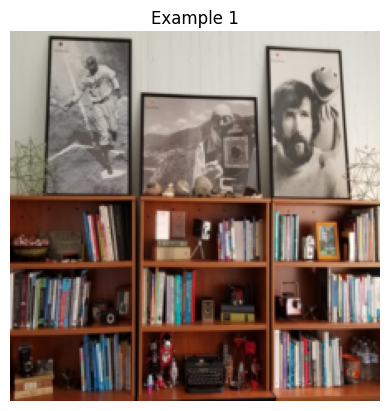

Image shape:  torch.Size([1, 3, 224, 224])
Results:  {'scores': tensor([], device='cuda:0', grad_fn=<IndexBackward0>), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'boxes': tensor([], device='cuda:0', size=(0, 4), grad_fn=<IndexBackward0>)}


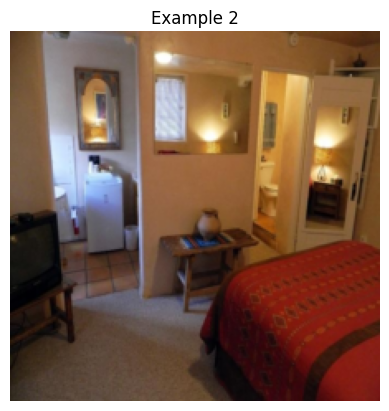

Image shape:  torch.Size([1, 3, 224, 224])
Results:  {'scores': tensor([], device='cuda:0', grad_fn=<IndexBackward0>), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'boxes': tensor([], device='cuda:0', size=(0, 4), grad_fn=<IndexBackward0>)}


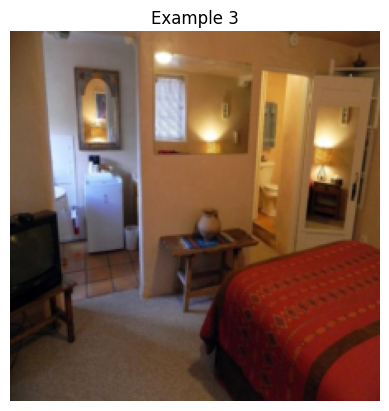

Image shape:  torch.Size([1, 3, 224, 224])
Results:  {'scores': tensor([], device='cuda:0', grad_fn=<IndexBackward0>), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'boxes': tensor([], device='cuda:0', size=(0, 4), grad_fn=<IndexBackward0>)}


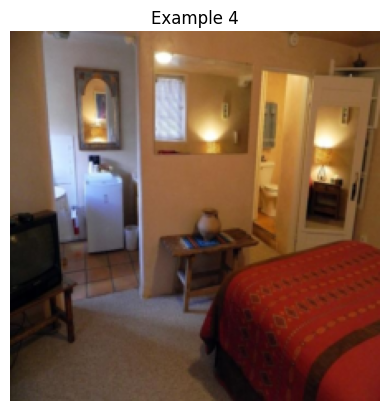

In [16]:
import numpy as np
import matplotlib.pyplot as plt

example_counter = 0
for image, data in inference_loader:
    if example_counter >= num_of_examples:
        break
    print("Image shape: ", image.shape)
    image = image[0]

    image_denorm = image * image_net_std + image_net_mean
    inputs = processor(images=image_denorm, return_tensors="pt").to(device)
    outputs = model(**inputs)

    target_sizes = torch.tensor([[image.shape[1], image.shape[2]]]).to(device)
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=0.5)[0]

    print("Results: ", results)

    for score, label, box in zip(results["scores"], results["labels"], results["boxes"]):
        box = [round(i, 2) for i in box.tolist()]
        print(
            f"Detected {model.config.id2label[label.item()]} with confidence "
            f"{round(score.item(), 3)} at location {box}"
        )

    if example_counter < num_display:
        image_np = image_denorm.cpu().numpy().transpose(1, 2, 0)
        image_np = np.clip(image_np, 0, 1)

        fig, ax = plt.subplots(1)
        ax.imshow(image_np)

        # Draw bounding boxes
        for score, label, box in zip(results["scores"], results["labels"], results["boxes"]):
            box = [round(i, 2) for i in box.tolist()]
            xmin, ymin, xmax, ymax = box
            rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color='red', linewidth=1)
            ax.add_patch(rect)
            ax.text(xmin, ymin - 5, f"{model.config.id2label[label.item()]}: {score:.2f}", fontsize=8, bbox=dict(facecolor='yellow', alpha=0.5))

        plt.title(f"Example {example_counter + 1}")
        plt.axis('off')
        plt.show()

    example_counter += 1